In [1]:
!pip install -q transformers datasets torch pandas openpyxl scikit-learn

In [4]:
import pandas as pd
import re

# 1. โหลดข้อมูล
excel_path = "/content/tu_scam_dataset_with emoji.xlsx"
df = pd.read_excel(excel_path)

# 2. สร้างฟังก์ชันทำความสะอาดข้อความเพื่อหา Base Template
def clean_text_for_grouping(text):
    text = re.sub(r'[^\w\s]', '', str(text))
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['clean_text'] = df['text'].apply(clean_text_for_grouping)

# 3. ตัดข้อมูลซ้ำโดยเลือกแถวแรกของแต่ละ Template
df_deduplicated = df.drop_duplicates(subset=['clean_text'], keep='first').copy()
df_deduplicated = df_deduplicated.drop(columns=['clean_text'])

# 4. แสดงจำนวนแถวแยกตามประเภท (Label) หลังตัดความซ้ำซ้อน
print("--- จำนวนแถวแยกตาม Label หลังตัดข้อมูลซ้ำ ---")
label_counts = df_deduplicated['label'].value_counts()
print(label_counts)

# 5. ทำ Label Encoding (เช่น normal=0, spam=1)
label_mapping = {'normal': 0, 'spam': 1}
df_deduplicated['label_encoded'] = df_deduplicated['label'].map(label_mapping)

print(f"\nจำนวนข้อมูลเดิม: {len(df)} แถว")
print(f"จำนวนข้อมูลหลังตัดความซ้ำซ้อน: {len(df_deduplicated)} แถว")

# แสดงตัวอย่างข้อมูลหลัง Encoding
print("\n--- ตัวอย่างข้อมูลหลัง Label Encoding ---")
print(df_deduplicated[['text', 'label', 'label_encoded']].head())

# 6. บันทึกไฟล์ใหม่
df_deduplicated.to_excel('tu_scam_dataset_deduplicated.xlsx', index=False)

--- จำนวนแถวแยกตาม Label หลังตัดข้อมูลซ้ำ ---
label
spam      651
normal    557
Name: count, dtype: int64

จำนวนข้อมูลเดิม: 1208 แถว
จำนวนข้อมูลหลังตัดความซ้ำซ้อน: 1208 แถว

--- ตัวอย่างข้อมูลหลัง Label Encoding ---
                                                text   label  label_encoded
0  บัญชีคุณถูกระงับ กรุณายืนยันตัวตนทันทีที่ tu-f...    spam              1
1        มีคนขอรหัสยืนยัน บอกว่าเป็นแอดมินกลุ่ม ASAP    spam              1
2  คุณได้รับสิทธิ์ทุนพิเศษ โอนค่าดำเนินการ 1500 บ...    spam              1
3  มีลิงก์ให้กรอกข้อมูลเพื่อรับสิทธิ์ ลองเช็คก่อน...    spam              1
4                          ขอแนวข้อสอบ MA211 น่อยคับ  normal              0


แถวทั้งหมด: 1208 | แถวที่มี emoji: 280 | แถวที่ลบ emoji แล้วไม่เท่า text: 13
⚠️ ตรวจสอบการจับคู่ id อีกครั้ง ตัวอย่างแถวที่ไม่ตรง:
      id                                               text  \
83    98   ขายหนังสือ  CS251  มือสอง  นัดรับ  โรงอาหารกล...   
100  121                 วันนี้ห้องเรียน  SC3  เปิดไหมครับ    
154  201   สมัครงานง่ายๆ  ได้เงินเร็ว  แต่ต้องจ่ายค่าสมั...   
188  259   พัสดุติดปัญหา  ชำระค่าธรรมเนียมที่  example.i...   
203  285   ใครเจอบัตรนักศึกษาที่  หอสมุดป๋วย  ทักมาหน่อย...   

                                            text_emoji  
83    ขายหนังสือ  CS251  มือสอง  นัดรับ  โรงอาหารกล...  
100                 วันนี้ห้องเรียน  SC3  เปิดไหมครับ   
154   สมัครงานง่ายๆ  ได้เงินเร็ว  แต่ต้องจ่ายค่าสมั...  
188   พัสดุติดปัญหา  ชำระค่าธรรมเนียมที่  example.i...  
203   ใครเจอบัตรนักศึกษาที่  หอสมุดป๋วย  ทักมาหน่อย...  
คลาสที่พบ: {0: 'normal', 1: 'scam'} | จำนวนต่อคลาส: {0: 557, 1: 651}
จำนวนกลุ่ม (template): 171


config.json:   0%|          | 0.00/642 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/527 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.26MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.4MB            

... (122 outputs left out)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] CamembertForSequenceClassification LOAD REPORT from: clicknext/phayathaibert
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
10,0.660034
20,0.611916
30,0.412018
40,0.243398
50,0.108156
60,0.106636
70,0.018779
80,0.069617
90,0.034897
100,0.035195


  PhayaThaiBERT (with emoji)   {'accuracy': 1.0, 'f1': 1.0, 'precision': 1.0, 'recall': 1.0} AUC: 1.0

🎯 สรุปผลรายfold 10 Folds (mean ± std)
                                   accuracy               f1        precision           recall              AUC
model                                                                                                          
LR (no emoji)               0.9285 ± 0.0899  0.9260 ± 0.0931  0.9351 ± 0.0873  0.9283 ± 0.0881  0.9868 ± 0.0243
PhayaThaiBERT (no emoji)    0.9694 ± 0.0327  0.9684 ± 0.0327  0.9711 ± 0.0291  0.9693 ± 0.0317  0.9943 ± 0.0070
PhayaThaiBERT (with emoji)  0.9593 ± 0.0453  0.9576 ± 0.0460  0.9612 ± 0.0411  0.9594 ± 0.0434  0.9932 ± 0.0082

📋 ตารางเปรียบเทียบ (รวมผลทุก fold)

[ภาพรวม]
                            accuracy  precision (macro)  recall (macro)  f1 (macro)
model                                                                              
LR (no emoji)                 0.9305             0.9373          0.9262      0.9293
P

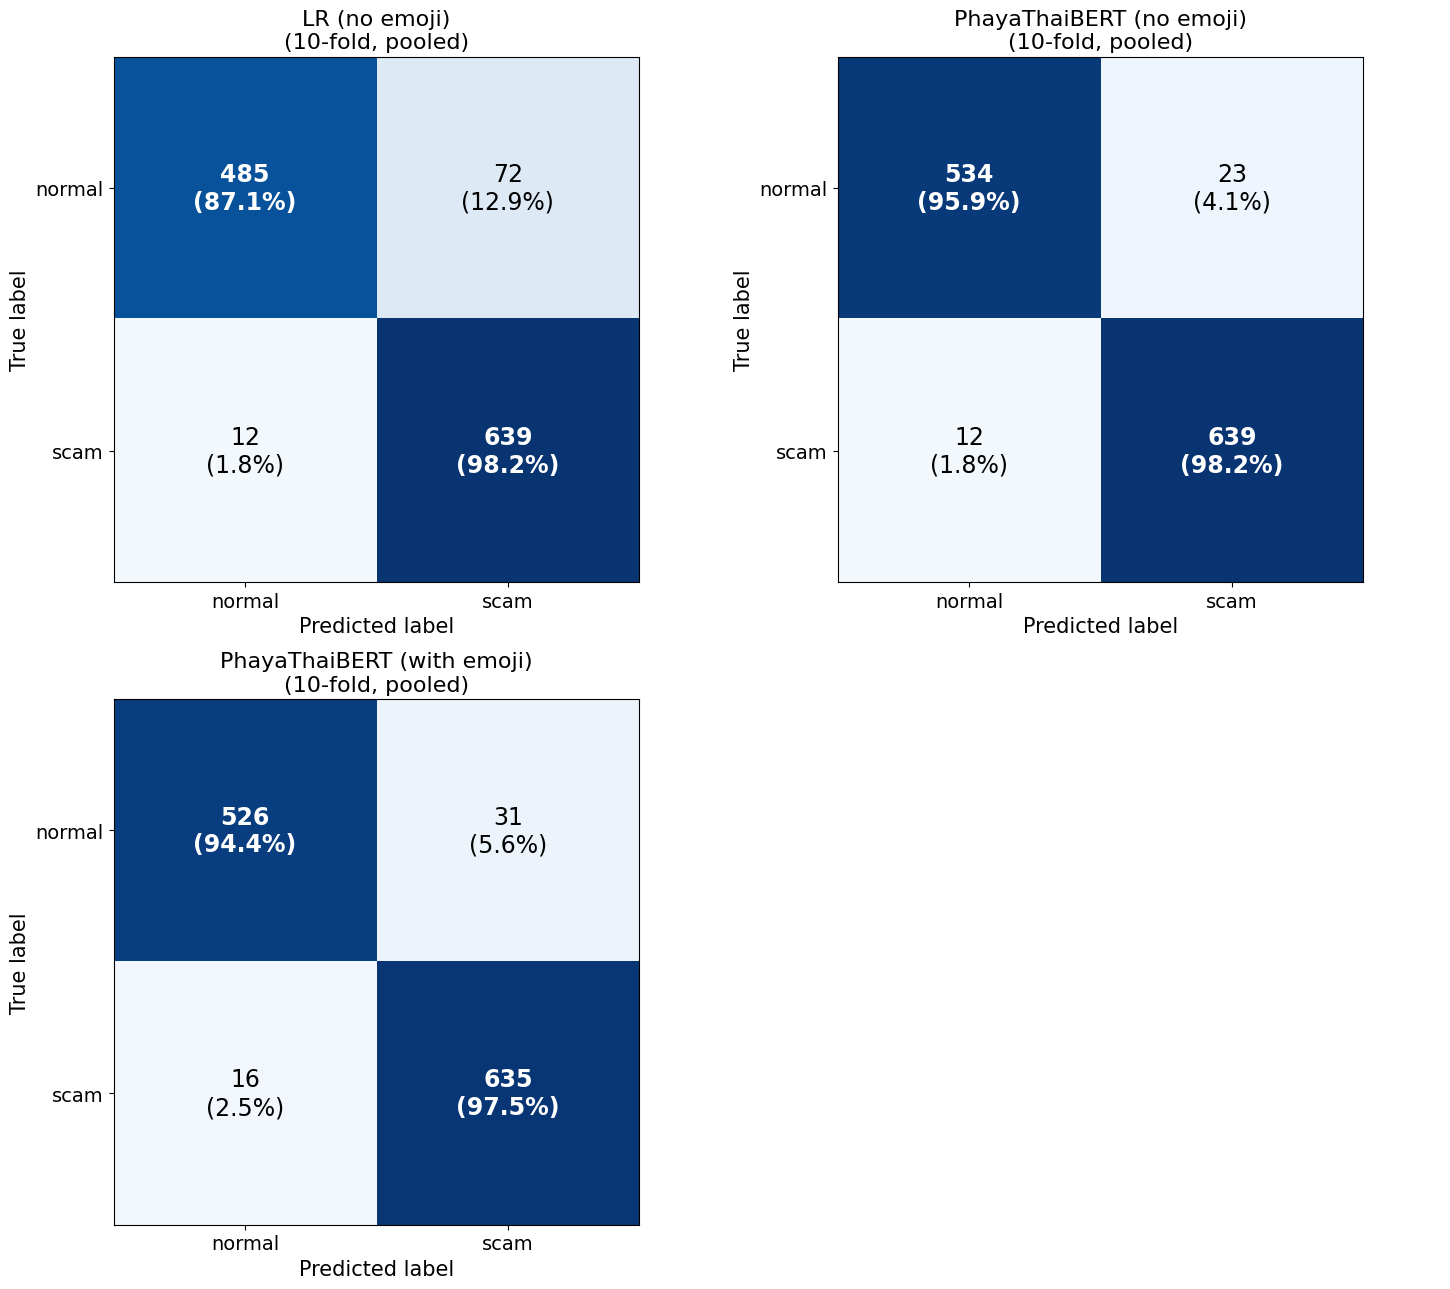

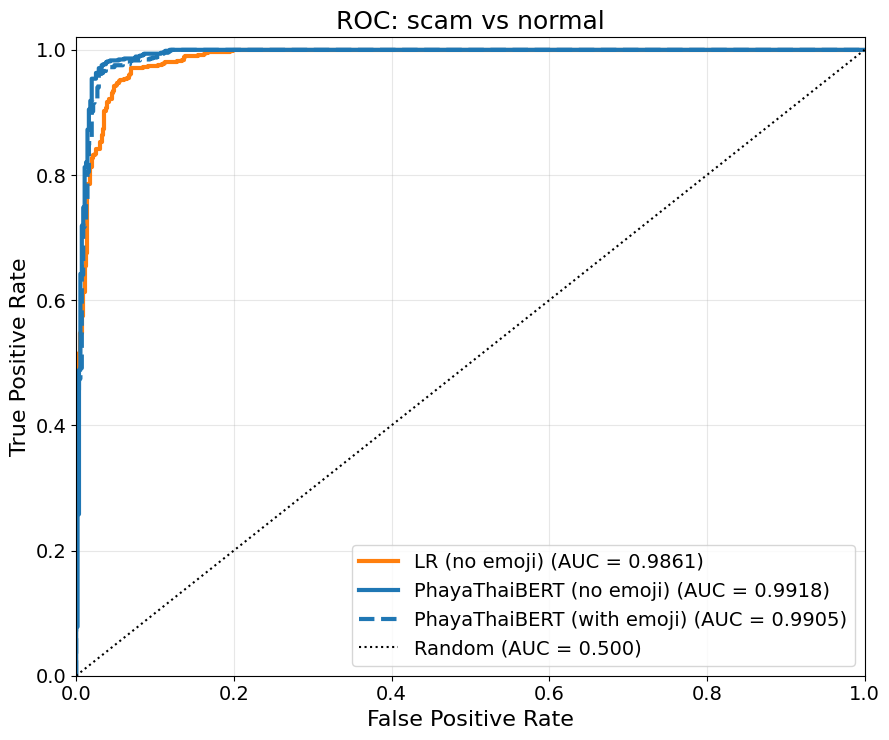


[AUC รวมทุก fold]
                            AUC (pooled)
LR (no emoji)                     0.9861
PhayaThaiBERT (no emoji)          0.9918
PhayaThaiBERT (with emoji)        0.9905

✅ บันทึกผล CV แล้ว: confusion_matrix_compare.png, roc_compare.png, metrics_overall.csv, metrics_per_class.csv, metrics_per_fold_mean_std.csv, auc_scores.csv

🏁 เทรนโมเดลสุดท้าย (no_emoji) ด้วยข้อมูลทั้งหมด...


Map:   0%|          | 0/1208 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] CamembertForSequenceClassification LOAD REPORT from: clicknext/phayathaibert
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
10,0.673590
20,0.569342
30,0.417697
40,0.247964
50,0.135471
60,0.066545
70,0.043635
80,0.098068
90,0.092565
100,0.009195


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (7 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
import json
import math
import re
import shutil

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from datasets import Dataset
from scipy.special import softmax
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding,
    set_seed,
)
from sklearn.cluster import AgglomerativeClustering
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    auc,
    confusion_matrix,
    precision_recall_fscore_support,
    roc_auc_score,
    roc_curve,
)
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold

SEED = 42
set_seed(SEED)

# ---------------------------------------------------------------
# ตั้งค่า
# ---------------------------------------------------------------
N_SPLITS = 10            # จำนวน fold
USE_GROUP_CV = True      # True = group-aware CV (วัด generalization จริง)

PATH_NO_EMOJI = "/content/tu_scam_dataset_no_emoji_de.xlsx"   # ไฟล์ที่ตัดซ้ำแล้ว (no emoji)
PATH_EMOJI = "/content/tu_scam_dataset_with_emoji_de.xlsx"        # ไฟล์ที่ตัดซ้ำแล้ว (with emoji)

# โมเดลสุดท้ายที่จะเทรนด้วยข้อมูลทั้งหมดแล้วเซฟ ([] = ไม่เซฟ)
SAVE_FINAL = ["no_emoji", "with_emoji"]

# ---------------------------------------------------------------
# 1. โหลดข้อมูล แล้วจับคู่ข้อความ with-emoji กับแถวเดียวกันด้วย id
#    (ใช้แถวชุดเดียวกัน ไม่ตัดซ้ำใหม่ เพื่อให้เทียบกันได้ยุติธรรม)
# ---------------------------------------------------------------
df = pd.read_excel(PATH_NO_EMOJI)
df_emoji = pd.read_excel(PATH_EMOJI)

assert "id" in df.columns and "id" in df_emoji.columns, "ต้องมีคอลัมน์ id ทั้งสองไฟล์"
df["id"] = df["id"].astype(int)
df_emoji["id"] = df_emoji["id"].astype(int)

emoji_text = df_emoji.set_index("id")["text"]
df["text_emoji"] = df["id"].map(emoji_text)
assert df["text_emoji"].notna().all(), "มี id ในไฟล์ no-emoji ที่หาไม่เจอในไฟล์ with-emoji"

# label_id
if "label_encoded" in df.columns:
    df["label_id"] = df["label_encoded"]
else:
    df["label_id"] = df["label"].map({"normal": 0, "spam": 1, "scam": 1})
assert df["label_id"].notna().all(), df.loc[df["label_id"].isna(), "label"].unique()
df["label_id"] = df["label_id"].astype(int)

# เช็กว่า label ของ 2 ไฟล์ตรงกัน
emoji_label = df_emoji.set_index("id")["label"]
assert (df["id"].map(emoji_label) == df["label"]).all(), "label ของ 2 ไฟล์ไม่ตรงกัน"

# เช็กว่า text_emoji ลบ emoji แล้วเท่ากับ text (ถ้าไม่เท่ากันแปลว่าจับคู่ผิดหรือแก้ข้อความอย่างอื่นไปด้วย)
EMOJI_RE = re.compile("[\U0001F000-\U0001FAFF\u2600-\u27BF\uFE0F\u200D\u203C]")
stripped = df["text_emoji"].apply(lambda t: EMOJI_RE.sub("", t).rstrip())
n_mismatch = int((stripped != df["text"]).sum())
print(f"แถวทั้งหมด: {len(df)} | แถวที่มี emoji: {int((df['text_emoji'] != df['text']).sum())} "
      f"| แถวที่ลบ emoji แล้วไม่เท่า text: {n_mismatch}")
if n_mismatch:
    print("⚠️ ตรวจสอบการจับคู่ id อีกครั้ง ตัวอย่างแถวที่ไม่ตรง:")
    print(df.loc[stripped != df["text"], ["id", "text", "text_emoji"]].head())

LABELS = sorted(df["label_id"].unique().tolist())
NUM_LABELS = len(LABELS)
label_names = ["normal", "scam"] if NUM_LABELS == 2 else [f"class_{i}" for i in LABELS]
id2label = {i: n for i, n in zip(LABELS, label_names)}
label2id = {n: i for i, n in id2label.items()}
print("คลาสที่พบ:", id2label, "| จำนวนต่อคลาส:", df["label_id"].value_counts().sort_index().to_dict())

# ---------------------------------------------------------------
# 2. สร้าง group จากข้อความ no-emoji (ใช้ group/split เดียวกันกับทุกโมเดล)
# ---------------------------------------------------------------
tfidf_group = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4))
X_group = tfidf_group.fit_transform(df["text"])
S = cosine_similarity(X_group)
df["group"] = AgglomerativeClustering(
    n_clusters=None,
    metric="precomputed",
    linkage="average",
    distance_threshold=0.2,
).fit_predict(1 - S)
print("จำนวนกลุ่ม (template):", df["group"].nunique())

# ---------------------------------------------------------------
# 3. Tokenizer + ฟังก์ชันช่วย
# ---------------------------------------------------------------
model_name = "clicknext/phayathaibert"
tokenizer = AutoTokenizer.from_pretrained(model_name)
collator = DataCollatorWithPadding(tokenizer)


def tokenize_function(examples):
    return tokenizer(examples["text"], truncation=True, max_length=64)


# ตรวจว่า tokenizer รู้จัก emoji ไหม (ถ้าถูกแปลงเป็น <unk> หมด ผล with-emoji จะไม่ต่างจาก no-emoji มาก)
changed = df[df["text_emoji"] != df["text"]]
unk_id = tokenizer.unk_token_id
n_unk = sum(unk_id in tokenizer(t)["input_ids"] for t in changed["text_emoji"])
print(f"[ตรวจ tokenizer] ข้อความที่มี emoji {len(changed)} แถว | มี <unk> {n_unk} แถว")


def macro_metrics(y_true, y_pred):
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    return {"accuracy": accuracy_score(y_true, y_pred), "f1": f1, "precision": p, "recall": r}


def make_args(output_dir, n_train):
    steps_per_epoch = int(np.ceil(n_train / 16))
    warmup_steps = int(0.1 * steps_per_epoch * 5)
    return TrainingArguments(
        output_dir=output_dir,
        num_train_epochs=5,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=32,
        learning_rate=2e-5,
        warmup_steps=warmup_steps,
        weight_decay=0.01,
        eval_strategy="no",
        save_strategy="no",
        logging_steps=10,
        seed=SEED,
        fp16=torch.cuda.is_available(),
        report_to="none",
    )


def new_model():
    return AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=NUM_LABELS, id2label=id2label, label2id=label2id
    )


def to_hf_dataset(d, text_col):
    ds = Dataset.from_pandas(
        d[[text_col, "label_id"]].rename(columns={text_col: "text", "label_id": "label"})
    )
    return ds.map(tokenize_function, batched=True)


def run_lr(train_df, val_df, text_col):
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4))
    Xtr = vec.fit_transform(train_df[text_col])
    Xva = vec.transform(val_df[text_col])
    lr = LogisticRegression(max_iter=2000)
    lr.fit(Xtr, train_df["label_id"])
    return lr.predict(Xva), lr.predict_proba(Xva)


def run_bert(train_df, val_df, text_col):
    train_ds = to_hf_dataset(train_df, text_col)
    val_ds = to_hf_dataset(val_df, text_col)
    model = new_model()
    trainer = Trainer(
        model=model,
        args=make_args("./tmp_cv", len(train_df)),
        train_dataset=train_ds,
        eval_dataset=val_ds,
        data_collator=collator,
    )
    trainer.train()
    proba = softmax(trainer.predict(val_ds).predictions, axis=-1)
    del model, trainer
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return np.argmax(proba, axis=-1), proba


# ---------------------------------------------------------------
# 4. กำหนดชุดการทดลอง (ชื่อ, ชนิดโมเดล, คอลัมน์ข้อความ)
# ---------------------------------------------------------------
EXPERIMENTS = [
    ("LR (no emoji)", "lr", "text"),
    ("PhayaThaiBERT (no emoji)", "bert", "text"),
]
EXPERIMENTS.append(("PhayaThaiBERT (with emoji)", "bert", "text_emoji"))

STYLE = {
    "LR (no emoji)": dict(color="tab:orange", ls="-"),
    "PhayaThaiBERT (no emoji)": dict(color="tab:blue", ls="-"),
    "PhayaThaiBERT (with emoji)": dict(color="tab:blue", ls="--"),
}

# ---------------------------------------------------------------
# 5. K-fold CV (split เดียว ใช้ร่วมกันทุกโมเดล)
# ---------------------------------------------------------------
if USE_GROUP_CV:
    splitter = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
    splits = list(splitter.split(df, df["label_id"], groups=df["group"]))
    print("โหมด: StratifiedGroupKFold (group-aware)")
else:
    splitter = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
    splits = list(splitter.split(df, df["label_id"]))
    print("โหมด: StratifiedKFold")

res = {name: {"pred": [], "proba": [], "fold_metrics": [], "fold_auc": []} for name, _, _ in EXPERIMENTS}
all_true = []
fold_true = []


def fold_auc(y, proba):
    try:
        if NUM_LABELS == 2:
            return roc_auc_score(y, proba[:, 1])
        return roc_auc_score(y, proba, multi_class="ovr", average="macro", labels=LABELS)
    except ValueError:
        return float("nan")


print(f"🚀 เริ่มต้น {N_SPLITS}-Fold Cross-Validation ({len(EXPERIMENTS)} โมเดลต่อ fold)...")

for fold, (train_idx, val_idx) in enumerate(splits):
    print(f"\n==================== Fold {fold + 1}/{N_SPLITS} ====================")
    train_df = df.iloc[train_idx].reset_index(drop=True)
    val_df = df.iloc[val_idx].reset_index(drop=True)
    y_val = val_df["label_id"].to_numpy()

    print("train class counts:", train_df["label_id"].value_counts().sort_index().to_dict())
    print("val   class counts:", val_df["label_id"].value_counts().sort_index().to_dict())
    print("กลุ่มที่ซ้ำกันระหว่าง train/val:", len(set(train_df["group"]) & set(val_df["group"])))

    all_true.extend(y_val.tolist())
    fold_true.append(y_val)

    for name, kind, col in EXPERIMENTS:
        pred, proba = run_lr(train_df, val_df, col) if kind == "lr" else run_bert(train_df, val_df, col)
        m = macro_metrics(y_val, pred)
        res[name]["pred"].extend(pred.tolist())
        res[name]["proba"].append(proba)
        res[name]["fold_metrics"].append(m)
        res[name]["fold_auc"].append(fold_auc(y_val, proba))
        print(f"  {name:<28}", {k: round(v, 4) for k, v in m.items()},
              "AUC:", round(res[name]["fold_auc"][-1], 4))

all_true = np.array(all_true)
for name in res:
    res[name]["pred"] = np.array(res[name]["pred"])
    res[name]["proba"] = np.vstack(res[name]["proba"])

# ---------------------------------------------------------------
# 6. สรุปผล
# ---------------------------------------------------------------
print("\n=======================================================")
print(f"🎯 สรุปผลรายfold {N_SPLITS} Folds (mean ± std)")
print("=======================================================")
fold_rows = []
for name in res:
    row = {"model": name}
    for key in ["accuracy", "f1", "precision", "recall"]:
        vals = [r[key] for r in res[name]["fold_metrics"]]
        row[key] = f"{np.mean(vals):.4f} ± {np.std(vals):.4f}"
    aucs = res[name]["fold_auc"]
    row["AUC"] = f"{np.nanmean(aucs):.4f} ± {np.nanstd(aucs):.4f}"
    fold_rows.append(row)
fold_df = pd.DataFrame(fold_rows).set_index("model")
print(fold_df.to_string())
fold_df.to_csv("metrics_per_fold_mean_std.csv")

print("\n=======================================================")
print("📋 ตารางเปรียบเทียบ (รวมผลทุก fold)")
print("=======================================================")
overall_rows, per_class_rows = [], []
for name in res:
    mm = macro_metrics(all_true, res[name]["pred"])
    overall_rows.append({
        "model": name,
        "accuracy": mm["accuracy"],
        "precision (macro)": mm["precision"],
        "recall (macro)": mm["recall"],
        "f1 (macro)": mm["f1"],
    })
    p, r, f1, sup = precision_recall_fscore_support(
        all_true, res[name]["pred"], labels=LABELS, zero_division=0
    )
    for i, lab in enumerate(LABELS):
        per_class_rows.append({
            "model": name, "class": id2label[lab],
            "precision": p[i], "recall": r[i], "f1": f1[i], "support": int(sup[i]),
        })
overall_df = pd.DataFrame(overall_rows).set_index("model")
per_class_df = pd.DataFrame(per_class_rows)
print("\n[ภาพรวม]")
print(overall_df.round(4).to_string())
print("\n[แยกรายคลาส]")
print(per_class_df.round(4).to_string(index=False))
overall_df.round(4).to_csv("metrics_overall.csv")
per_class_df.round(4).to_csv("metrics_per_class.csv", index=False)


# ---------------------------------------------------------------
# 7. Confusion matrix (ทุกโมเดล)
# ---------------------------------------------------------------
CM_TITLE_FS, CM_LABEL_FS, CM_TICK_FS, CM_ANNOT_FS = 16, 15, 14, 17   # ขนาดตัวอักษร confusion matrix


def plot_cm(ax, cm, title):
    row_sum = np.maximum(cm.sum(axis=1, keepdims=True), 1)
    cm_pct = cm / row_sum * 100
    ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
    n = len(LABELS)
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels(label_names, fontsize=CM_TICK_FS)
    ax.set_yticklabels(label_names, fontsize=CM_TICK_FS)
    ax.set_xlabel("Predicted label", fontsize=CM_LABEL_FS)
    ax.set_ylabel("True label", fontsize=CM_LABEL_FS)
    ax.set_title(title, fontsize=CM_TITLE_FS)
    for i in range(n):
        for j in range(n):
            ax.text(
                j, i, f"{cm[i, j]}\n({cm_pct[i, j]:.1f}%)",
                ha="center", va="center", fontsize=CM_ANNOT_FS,
                color="white" if cm_pct[i, j] > 50 else "black",
                fontweight="bold" if i == j else "normal",
            )


n_models = len(res)
ncols = 2
nrows = math.ceil(n_models / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(7.5 * ncols, 6.5 * nrows), squeeze=False)
for ax, name in zip(axes.flat, res):
    cm = confusion_matrix(all_true, res[name]["pred"], labels=LABELS)
    print(f"\nConfusion matrix รวมทุก fold ({name}):")
    print(cm)
    plot_cm(ax, cm, f"{name}\n({N_SPLITS}-fold, pooled)")
for ax in list(axes.flat)[n_models:]:
    ax.axis("off")
plt.tight_layout()
plt.savefig("confusion_matrix_compare.png", dpi=200, bbox_inches="tight")
plt.show()

# ---------------------------------------------------------------
# 8. ROC curve (ทุกโมเดลในกราฟเดียว)
#    2 คลาส: scam vs normal | มากกว่า 2 คลาส: macro-average แบบ One-vs-Rest
#    สี = ชนิดโมเดล (ส้ม=LR, น้ำเงิน=Phaya), เส้นทึบ = no emoji, เส้นประ = with emoji (เฉพาะ Phaya)
# ---------------------------------------------------------------
y_bin = (all_true[:, None] == np.array(LABELS)[None, :]).astype(int)
fpr_grid = np.linspace(0, 1, 500)


def get_roc(proba):
    if NUM_LABELS == 2:
        fpr, tpr, _ = roc_curve(y_bin[:, 1], proba[:, 1])
        return fpr, tpr, auc(fpr, tpr)
    tprs = []
    for i in range(NUM_LABELS):
        f, t, _ = roc_curve(y_bin[:, i], proba[:, i])
        tprs.append(np.interp(fpr_grid, f, t))
    mean_tpr = np.mean(tprs, axis=0)
    return fpr_grid, mean_tpr, auc(fpr_grid, mean_tpr)


roc_title = f"{label_names[1]} vs {label_names[0]}" if NUM_LABELS == 2 else "Macro-average (OvR)"
roc_results = {name: get_roc(res[name]["proba"]) for name in res}

ROC_TITLE_FS, ROC_LABEL_FS, ROC_TICK_FS, ROC_LEGEND_FS = 18, 16, 14, 14   # ขนาดตัวอักษร ROC

fig, ax = plt.subplots(figsize=(9, 7.5))
for name in res:
    fpr, tpr, a = roc_results[name]
    ax.plot(fpr, tpr, lw=3, label=f"{name} (AUC = {a:.4f})", **STYLE[name])
ax.plot([0, 1], [0, 1], "k:", lw=1.5, label="Random (AUC = 0.500)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_xlabel("False Positive Rate", fontsize=ROC_LABEL_FS)
ax.set_ylabel("True Positive Rate", fontsize=ROC_LABEL_FS)
ax.set_title(f"ROC: {roc_title}", fontsize=ROC_TITLE_FS)
ax.tick_params(labelsize=ROC_TICK_FS)
ax.legend(loc="lower right", fontsize=ROC_LEGEND_FS)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("roc_compare.png", dpi=200, bbox_inches="tight")
plt.show()

print("\n[AUC รวมทุก fold]")
auc_df = pd.DataFrame(
    {"AUC (pooled)": {name: roc_results[name][2] for name in res}}
)
print(auc_df.round(4).to_string())
auc_df.round(4).to_csv("auc_scores.csv")

print("\n✅ บันทึกผล CV แล้ว: confusion_matrix_compare.png, roc_compare.png, "
      "metrics_overall.csv, metrics_per_class.csv, metrics_per_fold_mean_std.csv, auc_scores.csv")


# ===============================================================
# 9. เทรนโมเดลสุดท้ายด้วยข้อมูลทั้งหมด แล้วเซฟเพื่อเอาไปใช้ข้างนอก
#    (ผล CV ด้านบนคือตัวเลขที่ใช้รายงาน ไม่ต้องวัดซ้ำบนโมเดลนี้)
# ===============================================================
FINAL_COLS = {"no_emoji": "text", "with_emoji": "text_emoji"}


def train_and_save(tag, text_col):
    save_dir = f"./phayathaibert_scam_final_{tag}"
    print(f"\n🏁 เทรนโมเดลสุดท้าย ({tag}) ด้วยข้อมูลทั้งหมด...")
    full_ds = to_hf_dataset(df, text_col)
    model = new_model()
    trainer = Trainer(
        model=model,
        args=make_args("./tmp_final", len(df)),
        train_dataset=full_ds,
        data_collator=collator,
    )
    trainer.train()
    trainer.save_model(save_dir)            # weights + config (มี id2label)
    tokenizer.save_pretrained(save_dir)     # tokenizer ต้องเซฟคู่กัน
    with open(f"{save_dir}/label_map.json", "w", encoding="utf-8") as f:
        json.dump(
            {"id2label": id2label, "max_length": 64, "base_model": model_name,
             "trained_with": tag},
            f, ensure_ascii=False, indent=2,
        )
    zip_path = shutil.make_archive(f"phayathaibert_scam_final_{tag}", "zip", save_dir)
    print(f"✅ บันทึกที่ {save_dir} และ {zip_path}")
    del model, trainer
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return zip_path


zip_paths = [train_and_save(tag, FINAL_COLS[tag]) for tag in SAVE_FINAL]

# ดาวน์โหลดลงเครื่อง (Colab)
try:
    from google.colab import files
    for zp in zip_paths:
        files.download(zp)
except ImportError:
    pass

# หรือเก็บลง Google Drive (เอา # ออกถ้าต้องการ)
# from google.colab import drive
# drive.mount("/content/drive")
# for tag in SAVE_FINAL:
#     shutil.copytree(f"./phayathaibert_scam_final_{tag}",
#                     f"/content/drive/MyDrive/phayathaibert_scam_final_{tag}", dirs_exist_ok=True)

# ---------------------------------------------------------------
# ตัวอย่างการโหลดไปใช้งานข้างนอก (ไม่ต้องใช้โค้ดเทรน):
#
#   from transformers import pipeline
#   clf = pipeline("text-classification", model="./phayathaibert_scam_final_no_emoji", top_k=None)
#   print(clf("บัญชีคุณถูกระงับ กรุณายืนยันตัวตนทันที"))
# ---------------------------------------------------------------